# Person B: TabNet experiments (Google Colab)

**Run:** Runtime → Run all. This notebook uses the team's `common/data.py`, `common/metrics.py` and `person_a/features.py`.

- German Credit: 5 × 5 repeated stratified CV, **TabNet categorical embeddings**.
- Fraud: temporal split, 29 baseline features, 5 random seeds.
- Saves each fold/seed immediately so an interruption doesn't lose all results.
- Outputs under `results/person_b/`, matching the team's repository structure.

**Note:** The runtime is an estimate, not a guarantee. TabNet on CPU can be substantially slower. Leave the Colab tab connected if possible; Colab can disconnect during unattended runs.


## 1. Install dependencies

## 2. Find your repository (or upload its ZIP)

In [1]:
from pathlib import Path
import os, sys

# Run from anywhere inside the repo (locally, or in Colab after cloning it).
ROOT = Path.cwd().resolve()
while not (ROOT / "common" / "data.py").exists():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Start the notebook from inside the repository folder.")
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
OUT = ROOT / "results" / "person_b"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)
print("Repository:", ROOT)

Repository: /home/claude/work


## 3. Imports and configuration

In [2]:
import gc, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import PrecisionRecallDisplay, ConfusionMatrixDisplay
from sklearn.calibration import calibration_curve
from pytorch_tabnet.tab_model import TabNetClassifier
from common.data import load_german, german_cv_splits, GERMAN_CATEGORICAL, GERMAN_NUMERIC, load_fraud, temporal_split
from common.metrics import all_metrics, german_cost
from person_a.features import base_features

# 10 seeds, matching XGBoost, fastai and Lightning. Set to 1 for a quick smoke test.
FRAUD_SEEDS = 10
GERMAN_MAX_EPOCHS = 80
FRAUD_MAX_EPOCHS = 60

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def tabnet_model(seed, cat_idxs=None, cat_dims=None):
    return TabNetClassifier(
        n_d=8, n_a=8, n_steps=3, gamma=1.3,
        cat_idxs=cat_idxs or [],
        cat_dims=cat_dims or [],
        cat_emb_dim=2,
        optimizer_fn=torch.optim.Adam,
        optimizer_params=dict(lr=0.02),
        mask_type="entmax",
        seed=seed,
        verbose=0,
        device_name="auto"
    )

print("PyTorch:", torch.__version__, "| GPU:", torch.cuda.is_available())


PyTorch: 2.15.0+cu132 | GPU: False


## 4. German Credit: 25 folds with categorical embeddings

Categorical codes are learned from each **inner training** subset only. Unknown categories map to code 0. Numeric scaling is also fitted only on inner training. Predictions are saved after each fold.


In [3]:
german = load_german()
GX = german.drop(columns=["bad"])
gy = german["bad"].to_numpy()
german_rows, german_preds = [], []
german_path = OUT / "tabnet_german_25fold_metrics.csv"
german_pred_path = OUT / "tabnet_german_25fold_predictions.csv"

for repeat, fold, tr_idx, te_idx in german_cv_splits(german):
    seed = 42 + repeat * 5 + fold
    set_seed(seed)
    fit_idx, val_idx = train_test_split(
        tr_idx, test_size=0.20, stratify=gy[tr_idx], random_state=seed
    )
    fit_raw, val_raw, test_raw = GX.iloc[fit_idx], GX.iloc[val_idx], GX.iloc[te_idx]
    scaler = StandardScaler()
    fit_num = scaler.fit_transform(fit_raw[GERMAN_NUMERIC]).astype("float32")
    val_num = scaler.transform(val_raw[GERMAN_NUMERIC]).astype("float32")
    test_num = scaler.transform(test_raw[GERMAN_NUMERIC]).astype("float32")

    fit_cats, val_cats, test_cats, cat_dims = [], [], [], []
    for col in GERMAN_CATEGORICAL:
        vocabulary = {v: j + 1 for j, v in enumerate(fit_raw[col].astype(str).unique())}
        encode = lambda series: series.astype(str).map(vocabulary).fillna(0).to_numpy(dtype="float32")
        fit_cats.append(encode(fit_raw[col]))
        val_cats.append(encode(val_raw[col]))
        test_cats.append(encode(test_raw[col]))
        cat_dims.append(len(vocabulary) + 1)

    def join_features(num, cats):
        return np.column_stack([num] + cats).astype("float32")

    Xfit = join_features(fit_num, fit_cats)
    Xval = join_features(val_num, val_cats)
    Xtest = join_features(test_num, test_cats)
    cat_idxs = list(range(len(GERMAN_NUMERIC), Xfit.shape[1]))
    model = tabnet_model(seed, cat_idxs=cat_idxs, cat_dims=cat_dims)
    start = time.time()
    model.fit(
        X_train=Xfit, y_train=gy[fit_idx],
        eval_set=[(Xval, gy[val_idx])],
        eval_name=["val"], eval_metric=["logloss"],
        max_epochs=GERMAN_MAX_EPOCHS, patience=12,
        batch_size=256, virtual_batch_size=64,
        num_workers=0, drop_last=False
    )
    p = model.predict_proba(Xtest)[:, 1]
    m = all_metrics(gy[te_idx], p)
    m.update(model="tabnet", dataset="german", repeat=repeat, fold=fold,
             encoding="categorical_embeddings", seed=seed,
             train_seconds=round(time.time()-start, 2),
             cost_05=german_cost(gy[te_idx], p >= 0.5),
             cost_0167=german_cost(gy[te_idx], p >= 1/6))
    german_rows.append(m)
    german_preds.extend(dict(repeat=repeat, fold=fold, row_index=int(idx),
                             actual=int(actual), predicted_probability=float(prob))
                        for idx, actual, prob in zip(te_idx, gy[te_idx], p))
    pd.DataFrame(german_rows).to_csv(german_path, index=False)
    pd.DataFrame(german_preds).to_csv(german_pred_path, index=False)
    print(f"German repeat {repeat+1}/5 fold {fold+1}/5 | PR-AUC={m['pr_auc']:.4f} | Brier={m['brier']:.4f} | Cost={m['cost_0167']:.4f}", flush=True)
    del model
    gc.collect()

german_results = pd.DataFrame(german_rows)
print("\nGERMAN RESULTS (25 folds):")
print(german_results[["pr_auc", "roc_auc", "brier", "rmse", "mae", "r2", "cost_05", "cost_0167"]].agg(["mean", "std"]).round(4).to_string())



Early stopping occurred at epoch 22 with best_epoch = 10 and best_val_logloss = 0.56213
German repeat 1/5 fold 1/5 | PR-AUC=0.4758 | Brier=0.1985 | Cost=0.7700



Early stopping occurred at epoch 20 with best_epoch = 8 and best_val_logloss = 0.58267
German repeat 1/5 fold 2/5 | PR-AUC=0.4690 | Brier=0.1973 | Cost=0.7050



Early stopping occurred at epoch 18 with best_epoch = 6 and best_val_logloss = 0.59017
German repeat 1/5 fold 3/5 | PR-AUC=0.4378 | Brier=0.1897 | Cost=0.5950



Early stopping occurred at epoch 22 with best_epoch = 10 and best_val_logloss = 0.59864
German repeat 1/5 fold 4/5 | PR-AUC=0.3859 | Brier=0.2181 | Cost=0.7600



Early stopping occurred at epoch 16 with best_epoch = 4 and best_val_logloss = 0.59866
German repeat 1/5 fold 5/5 | PR-AUC=0.3583 | Brier=0.2192 | Cost=0.7250



Early stopping occurred at epoch 21 with best_epoch = 9 and best_val_logloss = 0.5622
German repeat 2/5 fold 1/5 | PR-AUC=0.3969 | Brier=0.2059 | Cost=0.7650


... (16 outputs left out)


Early stopping occurred at epoch 17 with best_epoch = 5 and best_val_logloss = 0.58013
German repeat 5/5 fold 3/5 | PR-AUC=0.4060 | Brier=0.2074 | Cost=0.7050



Early stopping occurred at epoch 23 with best_epoch = 11 and best_val_logloss = 0.57671
German repeat 5/5 fold 4/5 | PR-AUC=0.4292 | Brier=0.2000 | Cost=0.6650



Early stopping occurred at epoch 19 with best_epoch = 7 and best_val_logloss = 0.59665
German repeat 5/5 fold 5/5 | PR-AUC=0.4229 | Brier=0.2027 | Cost=0.6900



GERMAN RESULTS (25 folds):
      pr_auc  roc_auc   brier    rmse    mae      r2  cost_05  cost_0167
mean  0.4501   0.6580  0.2009  0.4480  0.390  0.0432   1.3340     0.7034
std   0.0516   0.0515  0.0136  0.0152  0.019  0.0649   0.1417     0.0671


## 5. Fraud: temporal split, 5 seeds

Uses the same base features and temporal split as Person A. **Only training data** determines scaling and class weights. The validation set controls early stopping; the test set is held out. We save each seed's results immediately.

**Note:** Weighted training can produce poorly calibrated probabilities. The later calibration experiment will investigate this.


In [4]:
fraud = load_fraud()
FX = base_features(fraud)
fy = fraud["Class"].to_numpy().astype(int)
tr, va, te = temporal_split(fraud)
scale = StandardScaler()
Xtr = scale.fit_transform(FX.iloc[tr]).astype("float32")
Xva = scale.transform(FX.iloc[va]).astype("float32")
Xte = scale.transform(FX.iloc[te]).astype("float32")
ytr, yva, yte = fy[tr], fy[va], fy[te]
print("Fraud splits:", len(tr), len(va), len(te))
print("Fraud counts:", int(ytr.sum()), int(yva.sum()), int(yte.sum()))
print("Features:", Xtr.shape[1])

fraud_rows = []
fraud_probabilities = []
fraud_metrics_path = OUT / "tabnet_fraud_runs.csv"
fraud_pred_path = OUT / "tabnet_fraud_predictions.npz"

for seed in range(FRAUD_SEEDS):
    set_seed(42 + seed)
    model = tabnet_model(42 + seed)
    start = time.time()
    model.fit(
        X_train=Xtr, y_train=ytr,
        eval_set=[(Xva, yva)],
        eval_name=["val"], eval_metric=["logloss"],
        weights=1,  # automatic inverse-frequency weighting
        max_epochs=FRAUD_MAX_EPOCHS, patience=10,
        batch_size=2048, virtual_batch_size=256,
        num_workers=0, drop_last=False
    )
    pval = model.predict_proba(Xva)[:, 1]
    ptest = model.predict_proba(Xte)[:, 1]
    m = all_metrics(yte, ptest)
    m.update(model="tabnet", dataset="fraud", split="temporal",
             features="base", seed=seed,
             train_seconds=round(time.time()-start, 2),
             test_frauds=int(yte.sum()))
    fraud_rows.append(m)
    fraud_probabilities.append(ptest.astype("float32"))
    pd.DataFrame(fraud_rows).to_csv(fraud_metrics_path, index=False)
    np.savez_compressed(
        fraud_pred_path, test_idx=te, y_test=yte,
        probabilities=np.stack(fraud_probabilities)
    )
    if seed == 0:
        model.save_model(str(OUT / "tabnet_fraud_model"))
        np.savez_compressed(OUT / "tabnet_fraud_scaler.npz",
                            mean=scale.mean_, scale=scale.scale_,
                            feature_names=np.asarray(FX.columns, dtype=str))
    print(f"Fraud seed {seed+1}/{FRAUD_SEEDS} | PR-AUC={m['pr_auc']:.4f} | ROC-AUC={m['roc_auc']:.4f} | Brier={m['brier']:.4f} | Time={m['train_seconds']:.1f}s", flush=True)
    del model
    gc.collect()

fraud_results = pd.DataFrame(fraud_rows)
print("\nFRAUD RESULTS:")
print(fraud_results[["pr_auc", "roc_auc", "brier", "rmse", "mae", "r2"]].agg(["mean", "std"]).round(4).to_string())


Fraud splits: 59272 10460 29886
Fraud counts: 162 13 48
Features: 29



Early stopping occurred at epoch 19 with best_epoch = 9 and best_val_logloss = 0.00673


Successfully saved model at /home/claude/work/results/person_b/tabnet_fraud_model.zip
Fraud seed 1/10 | PR-AUC=0.6881 | ROC-AUC=0.9499 | Brier=0.0016 | Time=25.1s



Early stopping occurred at epoch 33 with best_epoch = 23 and best_val_logloss = 0.00759


Fraud seed 2/10 | PR-AUC=0.7737 | ROC-AUC=0.9505 | Brier=0.0012 | Time=42.1s



Early stopping occurred at epoch 30 with best_epoch = 20 and best_val_logloss = 0.0066


... (12 outputs left out)

Fraud seed 9/10 | PR-AUC=0.8159 | ROC-AUC=0.9535 | Brier=0.0010 | Time=39.8s



Early stopping occurred at epoch 25 with best_epoch = 15 and best_val_logloss = 0.00994


Fraud seed 10/10 | PR-AUC=0.7928 | ROC-AUC=0.9597 | Brier=0.0013 | Time=31.0s



FRAUD RESULTS:
      pr_auc  roc_auc   brier    rmse     mae      r2
mean  0.7823   0.9428  0.0011  0.0325  0.0015  0.3335
std   0.0418   0.0216  0.0003  0.0040  0.0004  0.1656


## 6. Graphs and framework comparisons


German Credit: Keras vs TabNet
        pr_auc  roc_auc   brier    rmse     mae  cost_05  cost_0167
model                                                              
keras   0.6096   0.7813  0.1668  0.4082  0.3236   0.9272     0.5494
tabnet  0.4501   0.6580  0.2009  0.4480  0.3900   1.3340     0.7034

Fraud: Person A vs TabNet (10 seeds each)
         pr_auc  roc_auc   brier    rmse     mae
model                                           
fastai   0.8546   0.9621  0.0004  0.0209  0.0033
tabnet   0.7823   0.9428  0.0011  0.0325  0.0015
xgboost  0.8754   0.9752  0.0004  0.0191  0.0007


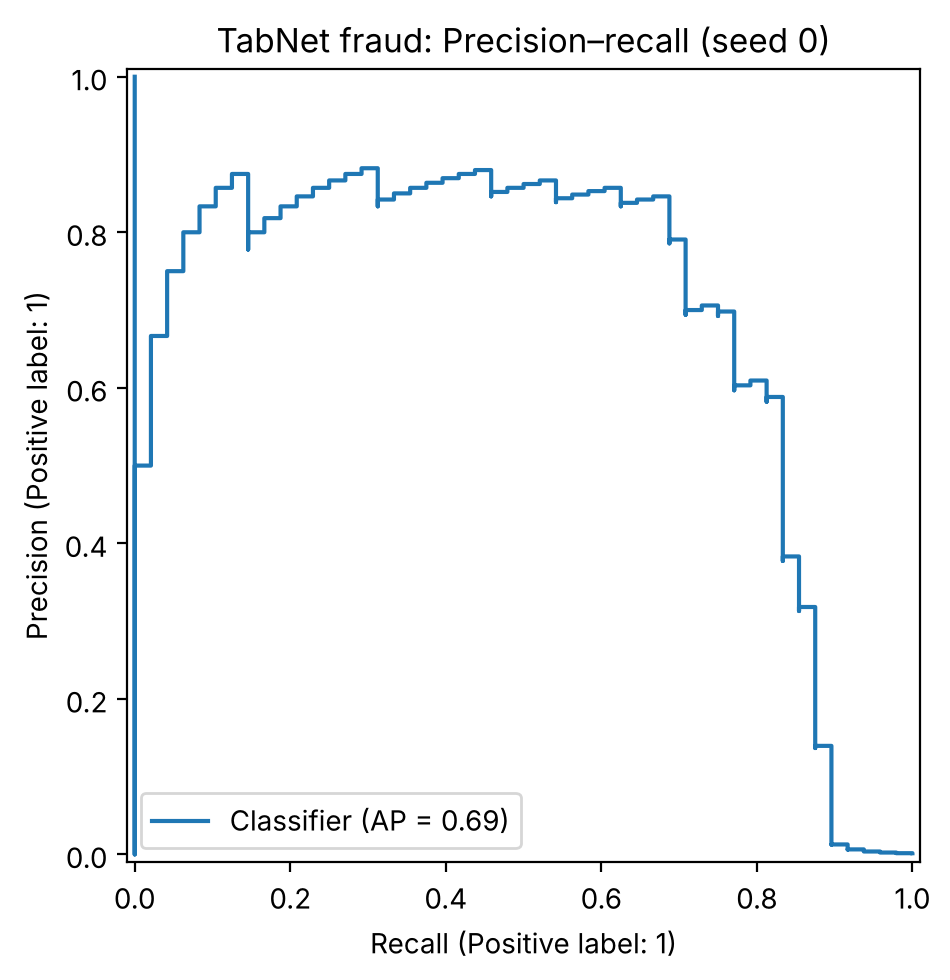

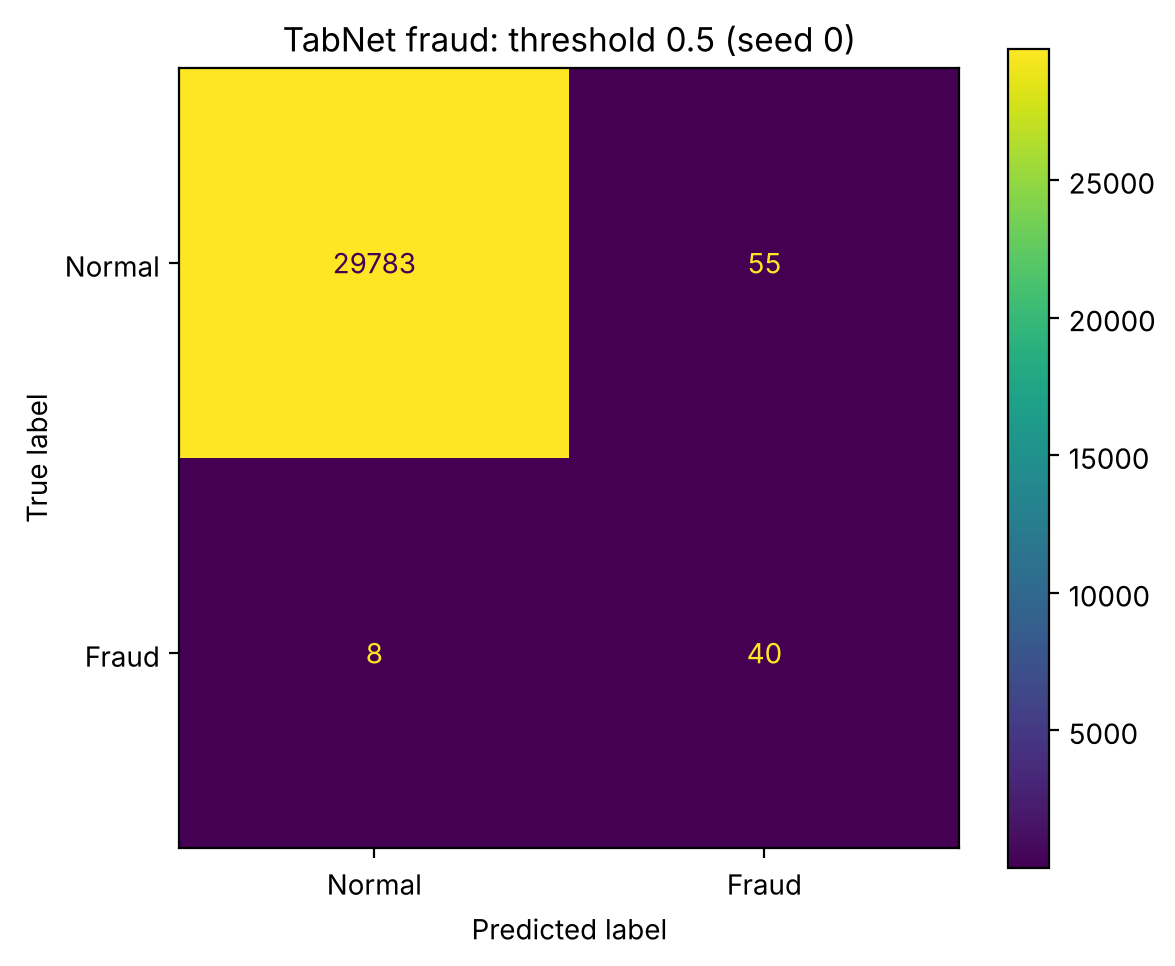

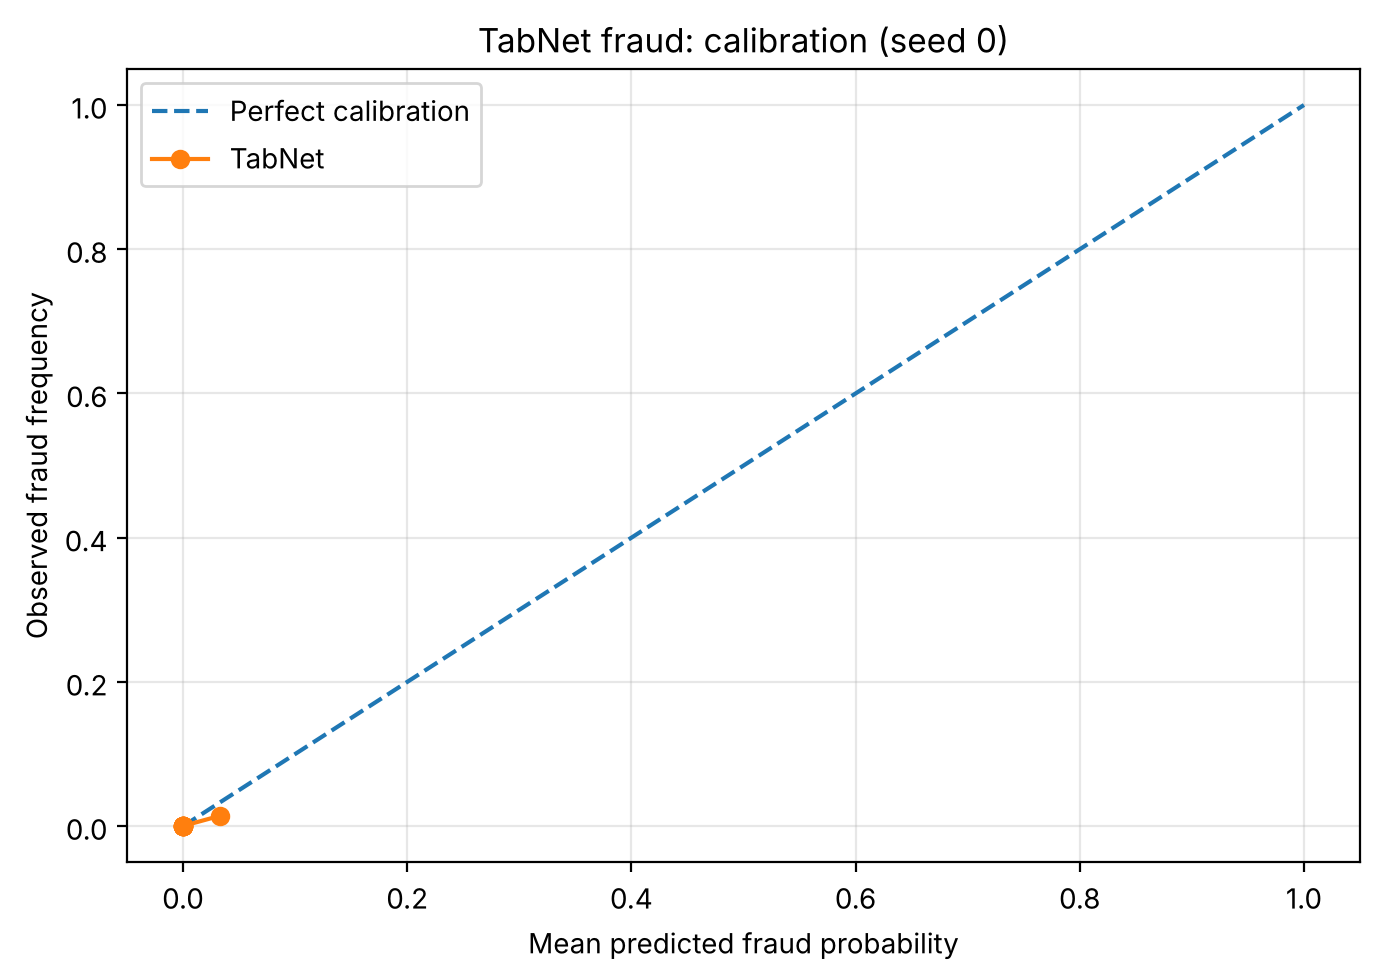

Figures saved to /home/claude/work/results/person_b/figures


In [5]:
from sklearn.metrics import average_precision_score

# German: comparison with previously saved Keras results (if available)
keras_german_candidates = [
    ROOT / "person_b/results/keras_german_25fold_metrics.csv",
    OUT / "keras_german_25fold_metrics.csv"
]
for f in keras_german_candidates:
    if f.exists():
        keras_german = pd.read_csv(f)
        compare = pd.concat([
            keras_german.assign(model="keras"),
            german_results.assign(model="tabnet")
        ], ignore_index=True)
        cols = ["pr_auc", "roc_auc", "brier", "rmse", "mae", "cost_05", "cost_0167"]
        print("\nGerman Credit: Keras vs TabNet")
        print(compare.groupby("model")[cols].mean().round(4).to_string())
        compare.groupby("model")[cols].agg(["mean", "std"]).to_csv(OUT / "tabnet_vs_keras_german.csv")
        break
else:
    print("Keras German results not found in this ZIP; you can compare later.")

# Fraud comparison with Person A (same split + feature set)
pa_file = ROOT / "results/person_a/fraud_runs.csv"
if pa_file.exists():
    pa = pd.read_csv(pa_file)
    pa = pa[(pa["split"] == "temporal") & (pa["features"] == "base")]
    both = pd.concat([pa, fraud_results], ignore_index=True)
    cols = ["pr_auc", "roc_auc", "brier", "rmse", "mae"]
    print("\nFraud: Person A vs TabNet (10 seeds each)")
    print(both.groupby("model")[cols].mean().round(4).to_string())
    both.groupby("model")[cols].agg(["mean", "std"]).to_csv(OUT / "tabnet_vs_person_a_fraud.csv")

p = fraud_probabilities[0]
fig, ax = plt.subplots(figsize=(7, 5))
PrecisionRecallDisplay.from_predictions(yte, p, ax=ax)
ax.set_title("TabNet fraud: Precision–recall (seed 0)")
fig.tight_layout()
fig.savefig(FIG / "tabnet_fraud_pr_curve.png", dpi=180)
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(yte, (p >= 0.5).astype(int),
                                       display_labels=["Normal", "Fraud"], ax=ax, values_format="d")
ax.set_title("TabNet fraud: threshold 0.5 (seed 0)")
fig.tight_layout()
fig.savefig(FIG / "tabnet_fraud_confusion.png", dpi=180)
plt.show()

fraction, mean_prob = calibration_curve(yte, p, n_bins=10, strategy="quantile")
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot([0,1], [0,1], "--", label="Perfect calibration")
ax.plot(mean_prob, fraction, "o-", label="TabNet")
ax.set(xlabel="Mean predicted fraud probability", ylabel="Observed fraud frequency",
       title="TabNet fraud: calibration (seed 0)")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG / "tabnet_fraud_calibration.png", dpi=180)
plt.show()
print("Figures saved to", FIG)


## 7. ZIP all results and download

## GitHub upload locations

- Notebook: `person_b/02_tabnet_models.ipynb`
- Results: `results/person_b/tabnet_*.csv`, `results/person_b/tabnet_*.npz`, `results/person_b/tabnet_fraud_model.zip`
- Figures: `results/person_b/figures/tabnet_*.png`

This notebook completes **TabNet modeling** on the two datasets. **Attention vs SHAP, categorical embeddings vs one-hot ablation, and detailed probability calibration are separate experiments**; they are not claimed as complete here.
